# 04b — Feature Engineering: home-shape features and the school district layer

**Week 6:** engineer new features, add a school district layer by spatially joining each home's coordinates to the *California School District Areas 2024-25* boundaries, re-train the Week 4–5 models, and compare old vs new feature sets.

Named 04b so that Week 7 keeps the plan's name `05_advanced_models.ipynb`.

Same setup as Week 5: Week 3 preprocessor, target `log(ClosePrice)`, train Jan 2025 – Mar 2026, test Apr 2026, Week 5 hyperparameters kept fixed (so any change comes from the features). The feature set is chosen on the Jan–Mar 2026 validation months; April is scored once.

**To beat (Random Forest, Week 5):** April MdAPE 7.58%, R² 0.906; validation mean MdAPE 7.51%.

## 1. Setup

In [1]:
import sys, json, time, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import sklearn, shapely
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

ROOT = next(p for p in [Path("."), Path("..")] if (p / "processed").exists()).resolve()
sys.path.insert(0, str(ROOT / "py"))
import preprocessing as pp
import modeling as mdl
import feature_engineering as fe

PROC, FIG_DIR = ROOT / "processed", ROOT / "figures" / "04b_feature_engineering"
RES_DIR = ROOT / "results"
for d in (FIG_DIR, RES_DIR): d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#2e9e6a", "#8a8984"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d0cfca", "grid.color": "#ecebe7",
                                     "axes.titleweight": "bold", "figure.dpi": 110})
def save(fig, name): fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=130)
def pct(v, d=2): return f"{v:.{d}f}%"

np.random.seed(pp.SEED)
cfg = json.loads((PROC / "preprocessing_config.json").read_text())
X_MONTHS, TEST_MONTH = cfg["train_window_months"], cfg["test_month"]
VAL_MONTHS = ["2026-01", "2026-02", "2026-03"]
run5 = json.loads((RES_DIR / "week5_run_info.json").read_text())
print(f"python {platform.python_version()} | scikit-learn {sklearn.__version__} | shapely {shapely.__version__} | X = {X_MONTHS} | test = {TEST_MONTH}")

python 3.13.18 | scikit-learn 1.7.2 | shapely 2.2.0 | X = 15 | test = 2026-04


## 2. Load data and add the home-shape features

In [2]:
clean = fe.add_home_features(mdl.load_clean(PROC / "sold_sfr_clean.csv"))
train_keys = pd.read_csv(PROC / "train.csv", usecols=["ListingKey"], dtype=str).ListingKey
test_keys = pd.read_csv(PROC / "test.csv", usecols=["ListingKey"], dtype=str).ListingKey
assert (clean.loc[clean.split == "train", "ListingKey"].values == train_keys.values).all()
assert (clean.loc[clean.split == "test", "ListingKey"].values == test_keys.values).all()
print(f"clean {len(clean):,} rows | train {len(train_keys):,} | test {len(test_keys):,}")

desc = clean.loc[clean.split == "train", fe.HOME_NUM].describe(percentiles=[0.01, 0.5, 0.99]).T
desc["missing_%"] = clean.loc[clean.split == "train", fe.HOME_NUM].isna().mean() * 100
desc[["count", "mean", "1%", "50%", "99%", "missing_%"]].round(3)

clean 306,122 rows | train 155,216 | test 12,175


,count,mean,1%,50%,99%,missing_%
beds_per_bath,155145.0,1.457,0.667,1.500,3.000,0.046
log_sqft_per_bed,155174.0,6.311,5.708,6.292,7.090,0.027
log_lot_to_living,152082.0,1.549,0.065,1.443,4.852,2.019


| Feature | Definition | Why it may help |
|---|---|---|
| `beds_per_bath` | bedrooms ÷ bathrooms | Many bedrooms on few bathrooms usually means an older or less updated layout |
| `log_sqft_per_bed` | log(living area ÷ bedrooms) | Room size: same square footage split into fewer, larger rooms sells for more |
| `log_lot_to_living` | log(lot size ÷ living area) | Land per square foot of house; separates large-lot rural homes from dense infill |

Age in years has been a model input since Week 3. All three use only the home's physical fields, never a price.

## 3. School district layer: spatial join

Each home's latitude/longitude is matched to the district polygon that contains it (`shapely` point-in-polygon). Elementary and high school districts overlap, so each home gets a K-8 district and a 9-12 district (both are the same unified district where one exists). Homes that fall in no polygon (coastline slivers) are snapped to the nearest district within 500 m.

In [3]:
boundary = fe.find_boundary_file(ROOT)
attrs, geoms = fe.load_districts(boundary)
print(f"{boundary.relative_to(ROOT)}: {len(attrs):,} district polygons")
print(attrs[fe.TYPE_COL].value_counts().to_string())

t = time.time()
join = fe.build_join_table(clean, boundary)
join.to_csv(PROC / "school_district_join.csv", index=False)
clean = fe.add_school_features(clean, join)
print(f"joined {len(join):,} homes in {time.time() - t:.0f} s -> processed/school_district_join.csv")

geo/California_School_District_Areas_2024-25.geojson: 937 district polygons
DistrictType
Elementary    516
Unified       345
High           76


joined 306,122 homes in 10 s -> processed/school_district_join.csv


In [4]:
cov = pd.DataFrame({
    "homes": [len(clean)],
    "matched_%": [clean.sd_elem_name.notna().mean() * 100],
    "snapped_to_nearest_%": [clean.sd_snapped.mean() * 100],
    "unmatched_%": [clean.sd_type.isna().mean() * 100],
    "unified_%": [(clean.sd_type == "Unified").mean() * 100],
    "elementary_plus_high_%": [(clean.sd_type == "Elementary + High").mean() * 100],
    "K-8 districts used": [clean.sd_elem_name.nunique()],
    "9-12 districts used": [clean.sd_high_name.nunique()],
    "MLS HighSchoolDistrict missing_%": [clean.HighSchoolDistrict.isna().mean() * 100],
}).T.rename(columns={0: "value"})
cov["value"] = cov["value"].map(lambda v: f"{v:,.2f}" if v % 1 else f"{v:,.0f}")
cov

,value
homes,"306,122"
matched_%,100.00
snapped_to_nearest_%,0.01
unmatched_%,0.00
unified_%,75.07
elementary_plus_high_%,24.93
K-8 districts used,686
9-12 districts used,404
MLS HighSchoolDistrict missing_%,33.13


**Spatial join vs the MLS `HighSchoolDistrict` field.** The MLS field is typed by agents and is blank for many homes; the join gives every home a district from official boundaries.

In [5]:
has_mls = clean.HighSchoolDistrict.notna()
norm = lambda s: (s.astype(str).str.replace(r"\s*\([^)]*\)$", "", regex=True)   # drop the "(County)" suffix
                  .str.lower().str.replace(r"(unified|union|joint|high|school|district|elementary|city|\W)", "", regex=True))
agree = (norm(clean.loc[has_mls, "HighSchoolDistrict"]) == norm(clean.loc[has_mls, "sd_high_name"])).mean() * 100
print(f"MLS field filled for {has_mls.mean():.1%} of homes; spatial join filled for {clean.sd_high_name.notna().mean():.1%}")
print(f"Where both exist, names match (after removing words like 'Unified', 'High') for {agree:.1f}% of homes")
mism = clean.loc[has_mls & (norm(clean.HighSchoolDistrict) != norm(clean.sd_high_name)), ["City", "HighSchoolDistrict", "sd_high_name"]]
mism.sample(6, random_state=pp.SEED)

MLS field filled for 66.9% of homes; spatial join filled for 99.9%
Where both exist, names match (after removing words like 'Unified', 'High') for 85.2% of homes


,City,HighSchoolDistrict,sd_high_name
126010,Murrieta,Murrieta,Murrieta Valley Unified (Riverside)
175193,Murrieta,Murrieta,Murrieta Valley Unified (Riverside)
199995,Perris,ABC Unified,Val Verde Unified (Riverside)
4251,Murrieta,Temecula Unified,Temecula Valley Unified (Riverside)
18194,Tujunga,Sacramento City Unified,Los Angeles Unified (Los Angeles)
184246,Murrieta,Murrieta,Murrieta Valley Unified (Riverside)


**District attributes** (from the same CDE file) for the K-8 district of each home, against price per sq ft of training sales.

,description,missing_%,median,rank corr with log $/sqft
sd_sed_pct,% socioeconomically disadvantaged students,0.001,66.600,-0.369
sd_el_pct,% English learners,0.001,15.970,0.048
sd_charter_pct,% of enrollment in charter schools,0.001,2.085,0.003
sd_log_enroll_density,log students per sq mi,0.001,5.695,0.460


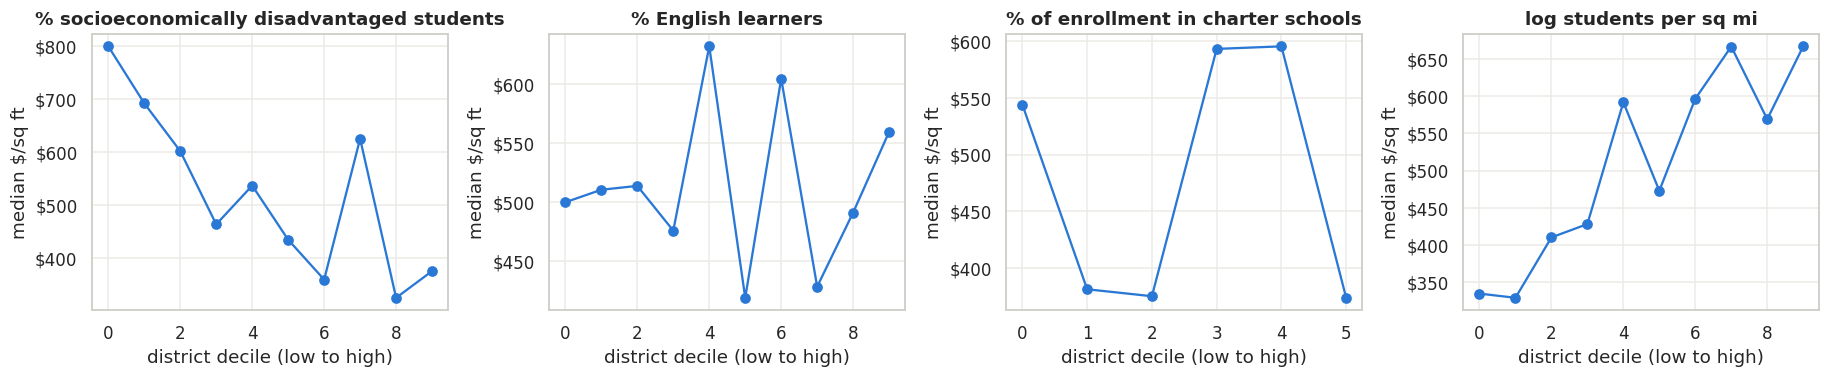

In [6]:
tr_all = clean[clean.split == "train"]
ppsf = np.log(tr_all.ClosePrice / tr_all.LivingArea)
attr_tab = pd.DataFrame({
    "description": [fe.SD_NUM_DESC[c] for c in fe.SD_NUM],
    "missing_%": [tr_all[c].isna().mean() * 100 for c in fe.SD_NUM],
    "median": [tr_all[c].median() for c in fe.SD_NUM],
    "rank corr with log $/sqft": [tr_all[c].corr(ppsf, method="spearman") for c in fe.SD_NUM],
}, index=fe.SD_NUM)
display(attr_tab.round(3))

n = len(fe.SD_NUM)
fig, ax = plt.subplots(1, n, figsize=(4.2 * n, 3.6), squeeze=False)
for a, c in zip(ax[0], fe.SD_NUM):
    q = pd.qcut(tr_all[c], 10, duplicates="drop")
    g = (tr_all.ClosePrice / tr_all.LivingArea).groupby(q, observed=True).median()
    a.plot(range(len(g)), g.values, marker="o", color=BLUE)
    a.set(title=fe.SD_NUM_DESC[c], xlabel="district decile (low to high)", ylabel="median $/sq ft")
    a.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
fig.tight_layout(); save(fig, "district_attributes_vs_ppsf"); plt.show()

## 4. Re-train with four feature sets

| Set | Inputs |
|---|---|
| A. Old (Week 5) | the 24 Week 3 inputs |
| B. + home shape | A + `beds_per_bath`, `log_sqft_per_bed`, `log_lot_to_living` |
| C. + school district | A + K-8 district, 9-12 district, district type, district attributes |
| D. New (all) | A + B + C |

Each model × set is scored on the three validation cutoffs (each cutoff refits its own preprocessor on its own window) and on April. Hyperparameters stay at the Week 5 values.

In [7]:
SETS = {"A. Old (Week 5)": fe.feature_set(),
        "B. + home shape": fe.feature_set(home=True),
        "C. + school district": fe.feature_set(school=True),
        "D. New (all)": fe.feature_set(home=True, school=True)}
for k, v in SETS.items(): print(f"{k:22s} {sum(len(x) for x in v.values())} inputs")

MODELS = {
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree": lambda: DecisionTreeRegressor(random_state=pp.SEED, **run5["decision_tree"]),
    "Random Forest": lambda: RandomForestRegressor(n_jobs=-1, random_state=pp.SEED, **run5["random_forest"]),
}
train, test = clean[clean.split == "train"], clean[clean.split == "test"]
y = test.ClosePrice.to_numpy()

rows, val_rows, pred, fitted = [], [], {}, {}
for mname, make in MODELS.items():
    for sname, fs in SETS.items():
        t = time.time()
        pipe = mdl.make_pipeline(make(), features=fs)
        bt, _ = mdl.rolling_backtest(clean, pipe, VAL_MONTHS, X_MONTHS)
        f = mdl.fit(pipe, train); p = mdl.predict_price(f, test)
        pred[(mname, sname)], fitted[(mname, sname)] = p, f
        val_rows += [{"model": mname, "feature_set": sname, "month": r.test_month, "MdAPE": r.MdAPE} for r in bt.itertuples()]
        rows.append({"model": mname, "feature_set": sname, "n_inputs": sum(len(x) for x in fs.values()),
                     "val_MdAPE": bt.MdAPE.mean(), **mdl.full_metrics(y, p), "sec": time.time() - t})
        print(f"{mname:18s} {sname:22s} val {bt.MdAPE.mean():.2f}% | April {rows[-1]['MdAPE']:.2f}% ({time.time() - t:.0f} s)")

res = pd.DataFrame(rows)
val_long = pd.DataFrame(val_rows)

A. Old (Week 5)        24 inputs
B. + home shape        27 inputs
C. + school district   32 inputs
D. New (all)           35 inputs


Linear Regression  A. Old (Week 5)        val 8.75% | April 8.63% (7 s)


Linear Regression  B. + home shape        val 8.66% | April 8.54% (7 s)


Linear Regression  C. + school district   val 8.72% | April 8.56% (10 s)


Linear Regression  D. New (all)           val 8.65% | April 8.51% (11 s)


...

Decision Tree      D. New (all)           val 9.11% | April 8.99% (22 s)


Random Forest      A. Old (Week 5)        val 7.51% | April 7.58% (293 s)


Random Forest      B. + home shape        val 7.54% | April 7.62% (362 s)


Random Forest      C. + school district   val 7.48% | April 7.53% (353 s)


Random Forest      D. New (all)           val 7.52% | April 7.60% (408 s)


Check: set A reproduces the Week 4–5 April results exactly.

In [8]:
prior = pd.read_csv(RES_DIR / "model_results.csv").set_index("model")
ref = {"Linear Regression": "Baseline: Linear Regression", "Decision Tree": "Week 5: Decision Tree", "Random Forest": "Week 5: Random Forest"}
for m, r in ref.items():
    got = res.query("model == @m and feature_set == 'A. Old (Week 5)'").MdAPE.iloc[0]
    assert np.isclose(got, prior.loc[r, "MdAPE"], atol=0.01), (m, got, prior.loc[r, "MdAPE"])
    print(f"{m:18s} April MdAPE {got:.2f}% (Week 4/5 file: {prior.loc[r, 'MdAPE']:.2f}%)")

Linear Regression  April MdAPE 8.63% (Week 4/5 file: 8.63%)
Decision Tree      April MdAPE 8.98% (Week 4/5 file: 8.98%)
Random Forest      April MdAPE 7.58% (Week 4/5 file: 7.58%)


## 5. Old vs new feature sets (deliverable table)

In [9]:
base = res[res.feature_set == "A. Old (Week 5)"].set_index("model")
res["val_change"] = res.val_MdAPE - res.model.map(base.val_MdAPE)
res["April_change"] = res.MdAPE - res.model.map(base.MdAPE)
res["R2_change"] = res.R2 - res.model.map(base.R2)
show = res[["model", "feature_set", "n_inputs", "val_MdAPE", "val_change", "MdAPE", "April_change", "R2", "R2_change",
            "MAPE", "MAE", "within_10pct", "median_bias_pct"]].copy()
fmt = {"val_MdAPE": "{:.2f}%", "val_change": "{:+.2f}", "MdAPE": "{:.2f}%", "April_change": "{:+.2f}", "R2": "{:.4f}",
       "R2_change": "{:+.4f}", "MAPE": "{:.2f}%", "MAE": "${:,.0f}", "within_10pct": "{:.1f}%", "median_bias_pct": "{:+.2f}%"}
for c, f in fmt.items(): show[c] = show[c].map(f.format)
show.rename(columns={"MdAPE": "April MdAPE", "val_MdAPE": "Val MdAPE", "val_change": "Val Δ (pts)",
                     "April_change": "April Δ (pts)", "R2": "April R²", "R2_change": "R² Δ"}).set_index(["model", "feature_set"])

n_inputs Val MdAPE Val Δ (pts) April MdAPE April Δ (pts) April R²     R² Δ    MAPE       MAE within_10pct  \
model             feature_set                                                                                                                       
Linear Regression A. Old (Week 5)             24     8.75%       +0.00       8.63%         +0.00   0.8886  +0.0000  12.02%  $161,003        56.2%   
                  B. + home shape             27     8.66%       -0.08       8.54%         -0.08   0.8878  -0.0008  11.98%  $160,839        56.3%   
                  C. + school district        32     8.72%       -0.03       8.56%         -0.07   0.8894  +0.0008  11.97%  $160,384        56.2%   
                  D. New (all)                35     8.65%       -0.10       8.51%         -0.11   0.8887  +0.0001  11.93%  $160,230        56.4%   
Decision Tree     A. Old (Week 5)             24     9.08%       +0.00       8.98%         +0.00   0.8857  +0.0000  12.64%  $168,812        54.0%   
                  B. + home shape             27     9.13%       +0.04       8.97%         -0.01   0.8861  +0.0004  12.66%  $168,685        54.1%   
                  C. + school district        32     9.07%       -0.01       9.06%         +0.08   0.8846  -0.0010  12.67%  $169,437        54.0%   
                  D. New (all)                35     9.11%       +0.03       8.99%         +0.01   0.8851  -0.0005  12.68%  $169,249        54.1%   
Random Forest     A. Old (Week 5)             24     7.51%       +0.00       7.58%         +0.00   0.9060  +0.0000  10.95%  $148,865        60.9%   
                  B. + home shape             27     7.54%       +0.02       7.62%         +0.04   0.9058  -0.0002  11.00%  $149,286        60.5%   
                  C. + school district        32     7.48%       -0.03       7.53%         -0.05   0.9063  +0.0003  10.89%  $148,440        61.2%   
                  D. New (all)                35     7.52%       +0.00       7.60%         +0.02   0.9065  +0.0005  10.95%  $149,039        61.0%   

                                       median_bias_pct  
model             feature_set                           
Linear Regression A. Old (Week 5)               -0.61%  
                  B. + home shape               -0.61%  
                  C. + school district          -0.45%  
                  D. New (all)                  -0.44%  
Decision Tree     A. Old (Week 5)               -1.68%  
                  B. + home shape               -1.68%  
                  C. + school district          -1.80%  
                  D. New (all)                  -1.81%  
Random Forest     A. Old (Week 5)               -1.41%  
                  B. + home shape               -1.51%  
                  C. + school district          -1.42%  
                  D. New (all)                  -1.49%

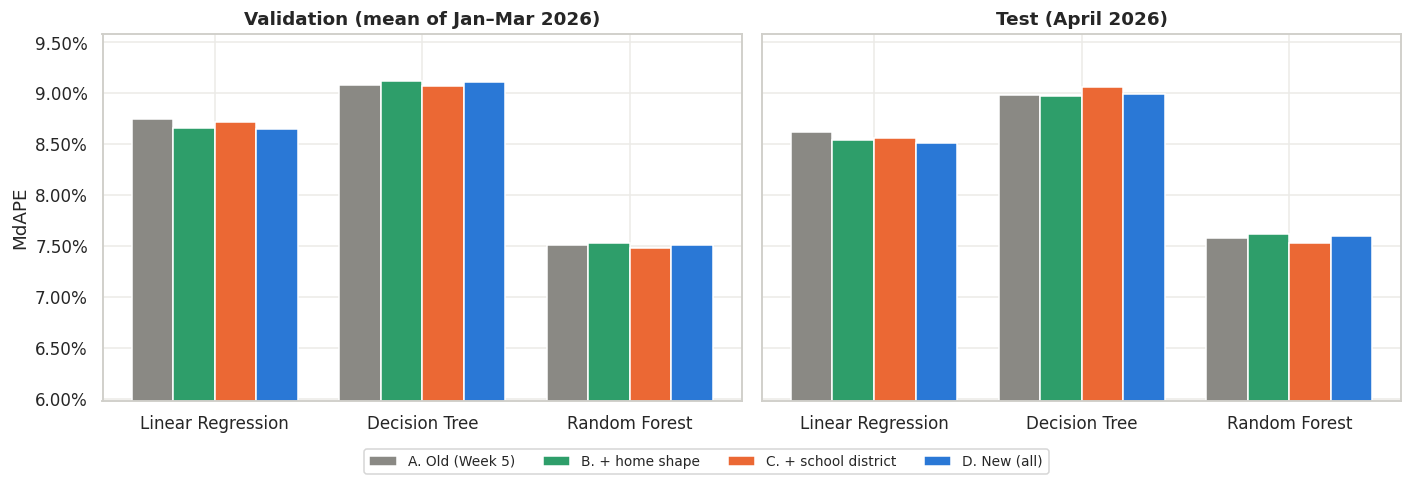

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
order = list(SETS)
cols = {order[0]: GREY, order[1]: GREEN, order[2]: ORANGE, order[3]: BLUE}
x, w = np.arange(len(MODELS)), 0.2
for i, s in enumerate(order):
    sub = res[res.feature_set == s].set_index("model").loc[list(MODELS)]
    ax[0].bar(x + (i - 1.5) * w, sub.val_MdAPE, w, color=cols[s], label=s)
    ax[1].bar(x + (i - 1.5) * w, sub.MdAPE, w, color=cols[s])
for a, t in zip(ax, ["Validation (mean of Jan–Mar 2026)", "Test (April 2026)"]):
    a.set_xticks(x, list(MODELS)); a.set_title(t); a.yaxis.set_major_formatter(mtick.PercentFormatter())
ax[0].set_ylabel("MdAPE"); fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.06))
lo = res[["val_MdAPE", "MdAPE"]].min().min(); ax[0].set_ylim(lo - 1.5, None)
fig.tight_layout(); save(fig, "old_vs_new_feature_sets"); plt.show()

**Is the gain bigger than the noise?** Change in MdAPE vs set A on each validation cutoff and on April (negative = better). Week 4 set a noise bar of about 0.4 points.

In [11]:
apr = res[["model", "feature_set", "MdAPE"]].assign(month=TEST_MONTH)
allm = pd.concat([val_long, apr]).pivot_table(index=["model", "feature_set"], columns="month", values="MdAPE")
delta = allm - allm.xs("A. Old (Week 5)", level="feature_set").reindex(allm.index, level="model")
delta = delta.drop(index="A. Old (Week 5)", level="feature_set")
delta["all_4_better"] = (delta < 0).all(axis=1)
delta.round(2)

month                                   2026-01  2026-02  2026-03  2026-04  all_4_better
model             feature_set                                                           
Decision Tree     B. + home shape          0.15    -0.08     0.05    -0.01         False
                  C. + school district    -0.01    -0.01    -0.01     0.08         False
                  D. New (all)             0.10    -0.02    -0.00     0.01         False
Linear Regression B. + home shape         -0.07    -0.09    -0.09    -0.08          True
                  C. + school district    -0.01    -0.04    -0.04    -0.07          True
                  D. New (all)            -0.05    -0.12    -0.11    -0.11          True
Random Forest     B. + home shape          0.01     0.05     0.01     0.04         False
                  C. + school district    -0.01    -0.03    -0.05    -0.05          True
                  D. New (all)            -0.04     0.07    -0.02     0.02         False

## 6. Where the new features help (Random Forest, old vs new)

Random Forest feature set chosen on validation: C. + school district


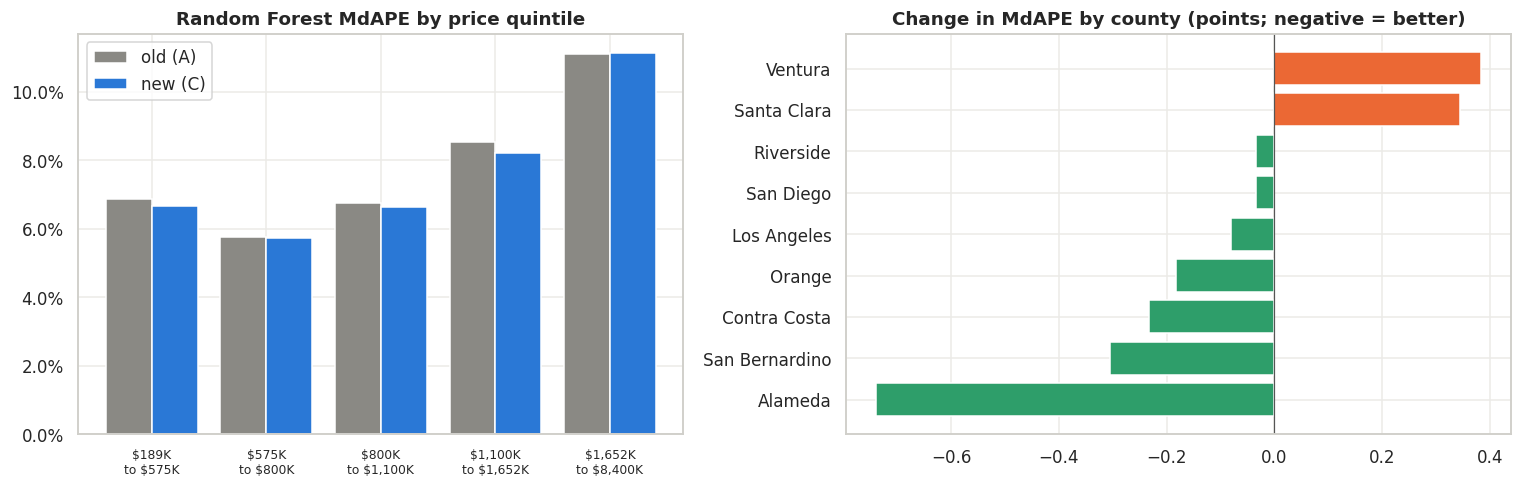

old                new            
                     MdAPE median_bias  MdAPE median_bias
g                                                        
Q1: $189K-$575K       6.88        1.92   6.66        1.89
Q2: $575K-$800K       5.77       -0.24   5.72       -0.29
Q3: $800K-$1,100K     6.75       -1.21   6.63       -1.20
Q4: $1,100K-$1,652K   8.54       -3.37   8.22       -3.25
Q5: $1,652K-$8,400K  11.08       -6.81  11.13       -6.84

In [12]:
SEL = res[res.model == "Random Forest"].sort_values("val_MdAPE").feature_set.iloc[0]   # chosen on validation only
p_old, p_new = pred[("Random Forest", "A. Old (Week 5)")], pred[("Random Forest", SEL)]
print("Random Forest feature set chosen on validation:", SEL)

bands = mdl.price_bands(y, 5)
b = pd.concat({"old": mdl.error_by_group(y, p_old, bands)[["MdAPE", "median_bias"]],
               "new": mdl.error_by_group(y, p_new, bands)[["MdAPE", "median_bias"]]}, axis=1)
county = test.CountyOrParish.to_numpy()
top = pd.Series(county).value_counts().loc[lambda s: s >= 300].index
mk = np.isin(county, top)
cty = pd.concat({"old": mdl.error_by_group(y[mk], p_old[mk], county[mk])["MdAPE"],
                 "new": mdl.error_by_group(y[mk], p_new[mk], county[mk])["MdAPE"]}, axis=1)
cty["change"] = cty.new - cty.old
cty = cty.sort_values("change")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
xx = np.arange(len(b))
ax[0].bar(xx - 0.2, b[("old", "MdAPE")], 0.4, color=GREY, label="old (A)")
ax[0].bar(xx + 0.2, b[("new", "MdAPE")], 0.4, color=BLUE, label=f"new ({SEL[:1]})")
ax[0].set_xticks(xx, [l.split(": ")[1].replace("-", "\nto ").replace("$", r"\$") for l in b.index], fontsize=8)
ax[0].set_title("Random Forest MdAPE by price quintile"); ax[0].legend(); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter())
ax[1].barh(cty.index, cty.change, color=np.where(cty.change < 0, GREEN, ORANGE))
ax[1].axvline(0, color="#555", lw=0.8); ax[1].set_title("Change in MdAPE by county (points; negative = better)")
fig.tight_layout(); save(fig, "rf_old_vs_new_by_band_and_county"); plt.show()
b.round(2)

**What the new Random Forest uses** (impurity importance; correlated location inputs share credit, so read as descriptive). New Week 6 inputs in blue.

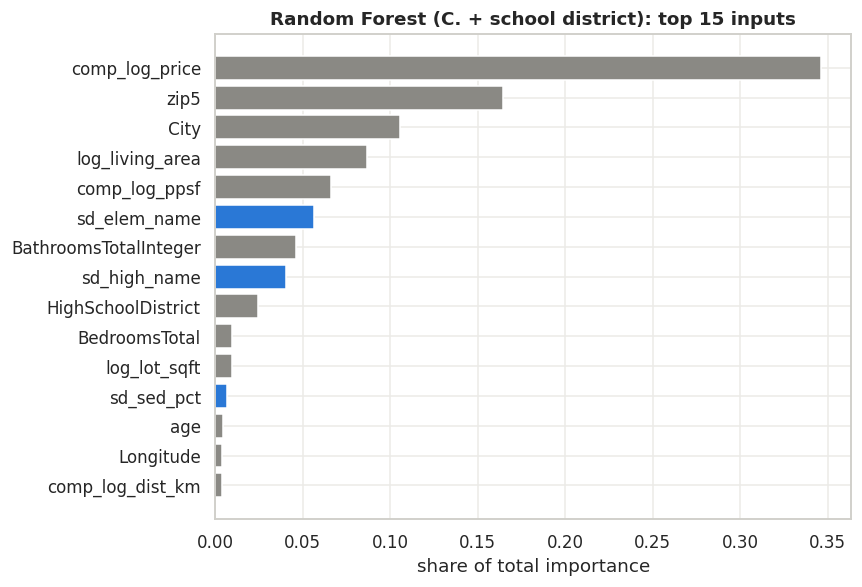

Share of importance on new Week 6 inputs: 10.9%


In [13]:
rf = fitted[("Random Forest", SEL)]
names = pd.Series(rf.named_steps["prep"].get_feature_names_out()).str.replace(r"^(num|bin|low|high)__", "", regex=True)
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values()
new_cols = set(fe.HOME_NUM + fe.SD_NUM + fe.SD_HIGHCARD) | {n for n in names if n.startswith(("sd_type", "sd_assist"))}
top15 = imp.tail(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top15.index, top15.values, color=[BLUE if n in new_cols else GREY for n in top15.index])
ax.set(title=f"Random Forest ({SEL}): top 15 inputs", xlabel="share of total importance")
fig.tight_layout(); save(fig, "rf_feature_importance_new"); plt.show()
print(f"Share of importance on new Week 6 inputs: {imp[imp.index.isin(new_cols)].sum():.1%}")

## 7. Save

In [14]:
best_by_model = res.loc[res.groupby("model").val_MdAPE.idxmin()].set_index("model")
new_rows = []
for m in MODELS:
    r = best_by_model.loc[m]
    new_rows.append({"model": f"Week 6: {m} ({r.feature_set})", **{k: r[k] for k in prior.columns if k in r.index},
                     "test_month": TEST_MONTH, "train_window_months": X_MONTHS, "train_rows": len(train),
                     "validation_MdAPE_mean": r.val_MdAPE})
out = pd.concat([prior.reset_index()[lambda d: ~d.model.str.startswith("Week 6")], pd.DataFrame(new_rows)], ignore_index=True)
out[prior.reset_index().columns].to_csv(RES_DIR / "model_results.csv", index=False)

res.drop(columns="sec").to_csv(RES_DIR / "week6_feature_set_comparison.csv", index=False)
allm.to_csv(RES_DIR / "week6_backtest_mdape.csv")
cty.to_csv(RES_DIR / "week6_rf_error_by_county.csv")
test[["ListingKey", "close_month", "CountyOrParish", "sd_elem_name", "ClosePrice"]].assign(
    **{f"pred_{m.lower().replace(' ', '_')}_{s[0]}": pred[(m, s)].round(0) for m in MODELS for s in SETS}
).to_csv(RES_DIR / "week6_test_predictions.csv", index=False)
(RES_DIR / "week6_run_info.json").write_text(json.dumps({
    "feature_sets": SETS, "chosen_on_validation": {m: best_by_model.loc[m, "feature_set"] for m in MODELS},
    "hyperparameters": {"decision_tree": run5["decision_tree"], "random_forest": run5["random_forest"]},
    "school_district_source": {"file": str(boundary.relative_to(ROOT)), "dataset": "California School District Areas 2024-25 (CDE)",
                               "numeric_attributes": fe.SD_NUM_DESC, "excluded": "race/ethnicity fields (fair housing); file ELpct (mis-scaled)", "snap_m": 500},
    "seed": pp.SEED, "test_month": TEST_MONTH,
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "shapely": shapely.__version__}}, indent=2))
pd.read_csv(RES_DIR / "model_results.csv")[["model", "MdAPE", "R2", "validation_MdAPE_mean"]].round(4)

,model,MdAPE,R2,validation_MdAPE_mean
0,Reference: comp median price (no model),12.0283,0.7066,NaN
1,Reference: comp price/sq ft x living area (no ...,12.7087,0.8606,NaN
2,Baseline: Linear Regression,8.6252,0.8886,8.7466
3,Week 5: Decision Tree,8.9818,0.8857,9.0836
4,Week 5: Random Forest,7.5792,0.9060,7.5141
5,Week 6: Linear Regression (D. New (all)),8.5106,0.8887,8.6508
6,Week 6: Decision Tree (C. + school district),9.0606,0.8846,9.0747
7,Week 6: Random Forest (C. + school district),7.5306,0.9063,7.4840


## 8. Summary

In [15]:
for m in MODELS:
    a, n = base.loc[m], best_by_model.loc[m]
    print(f"{m:18s} old {a.MdAPE:.2f}% -> {n.feature_set:22s} {n.MdAPE:.2f}% (April) | val {a.val_MdAPE:.2f}% -> {n.val_MdAPE:.2f}% | R2 {a.R2:.4f} -> {n.R2:.4f}")

Linear Regression  old 8.63% -> D. New (all)           8.51% (April) | val 8.75% -> 8.65% | R2 0.8886 -> 0.8887
Decision Tree      old 8.98% -> C. + school district   9.06% (April) | val 9.08% -> 9.07% | R2 0.8857 -> 0.8846
Random Forest      old 7.58% -> C. + school district   7.53% (April) | val 7.51% -> 7.48% | R2 0.9060 -> 0.9063


**Findings**

| Model | Old → best new set (chosen on validation) | Validation MdAPE | April MdAPE | April R² |
|---|---|---|---|---|
| Linear Regression | A → D. New (all) | 8.75% → 8.65% | 8.63% → 8.51% | 0.8886 → 0.8887 |
| Decision Tree | A → C. + school district | 9.08% → 9.07% | 8.98% → 9.06% | 0.8857 → 0.8846 |
| **Random Forest** | A → C. + school district | 7.51% → 7.48% | **7.58% → 7.53%** | 0.9060 → 0.9063 |

- **The school district layer works as data**: every home gets a district from official boundaries (the MLS field is blank for 33% of homes and disagrees with the boundaries for about 15% of the rest). The two district names take ~10% of the Random Forest's importance.
- **But the accuracy gain is small.** No feature set beats the old one by the ~0.4-point noise bar from Week 4. Linear Regression improves on all four cutoffs (−0.05 to −0.12 points with all new features); Random Forest with the school layer improves on all four cutoffs but by only 0.01–0.05 points. The Decision Tree does not improve.
- **Why:** ZIP, City, the MLS high-school district and the 10 nearest comps already describe location very finely, so district boundaries add little that is new. The home-shape features help the linear model (it cannot form size ÷ rooms itself) but not the trees (which can split on size and rooms together).
- Where the school layer helps the Random Forest most: Alameda (−0.74 points), San Bernardino, Contra Costa; it is worse in Ventura and Santa Clara. The top price quintile is still under-predicted (−6.8% bias).

**Decision for Week 7:** carry forward set C (Week 3 inputs + school district layer) for tree models: it is the best on validation, costs nothing at prediction time (district lookup from coordinates), and gives full district coverage. Keep the home-shape features available for linear models. Gradient boosting (Week 7) starts from Random Forest C: April MdAPE 7.53%, validation 7.48%.